In [1]:
# import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
%matplotlib inline

In [2]:
# Import data
insurance_data = pd.read_csv('insurance.csv')
insurance_data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Multiple Linear Regression

In [3]:
X = insurance_data.iloc[:,[0, 1, 2, 3, 4, 5]].values
X[1:5]

array([[18, 'male', 33.77, 1, 'no', 'southeast'],
       [28, 'male', 33.0, 3, 'no', 'southeast'],
       [33, 'male', 22.705, 0, 'no', 'northwest'],
       [32, 'male', 28.88, 0, 'no', 'northwest']], dtype=object)

There are multiple factors contributing on the insurance costs. Let us take a look at the relationship between age, sex, bmi, children, smoker and region and see how this affects insurance charges

FacetGrid Plot 1
Charges vs Age by Sex and Smoker

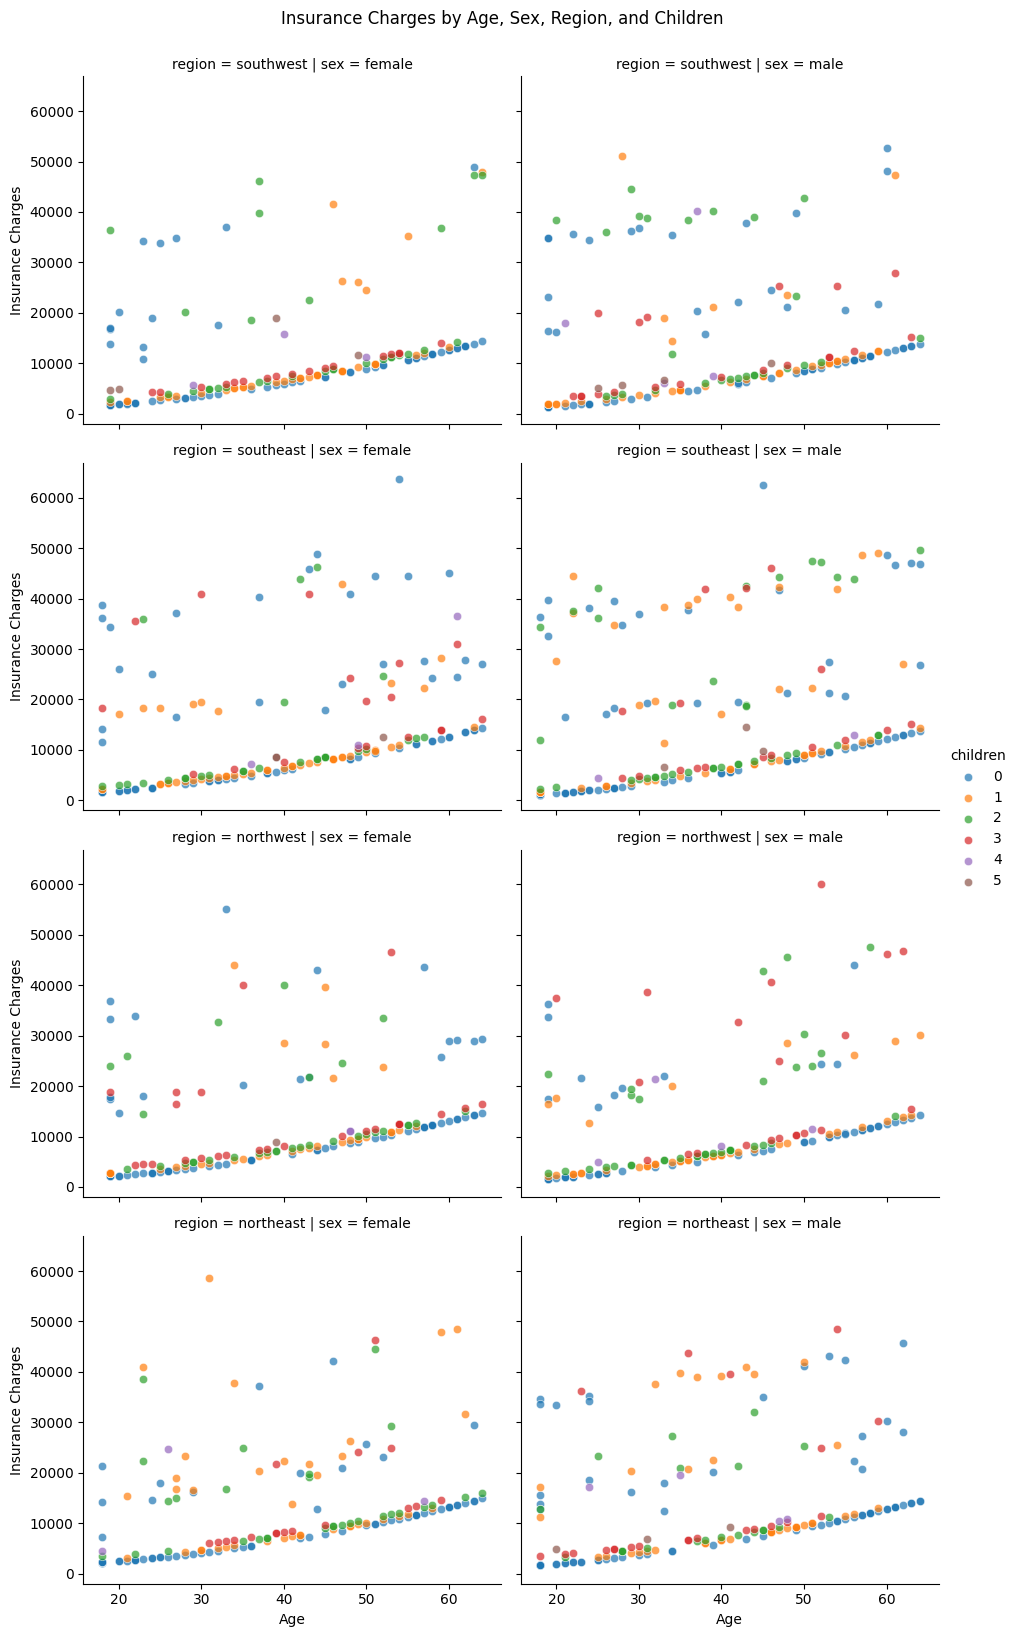

In [4]:
fg = sns.FacetGrid(insurance_data, col="sex", row="region", hue="children", height=4, aspect=1.2)
fg.map(sns.scatterplot, "age", "charges", alpha=0.7)

# Add legend
fg.add_legend()

# Add title
fg.set_axis_labels("Age", "Insurance Charges")
fg.fig.suptitle("Insurance Charges by Age, Sex, Region, and Children", y=1.02)

# Show plot
plt.show()

FacetGrid plot 2
Charges by bmi, sex and smoker


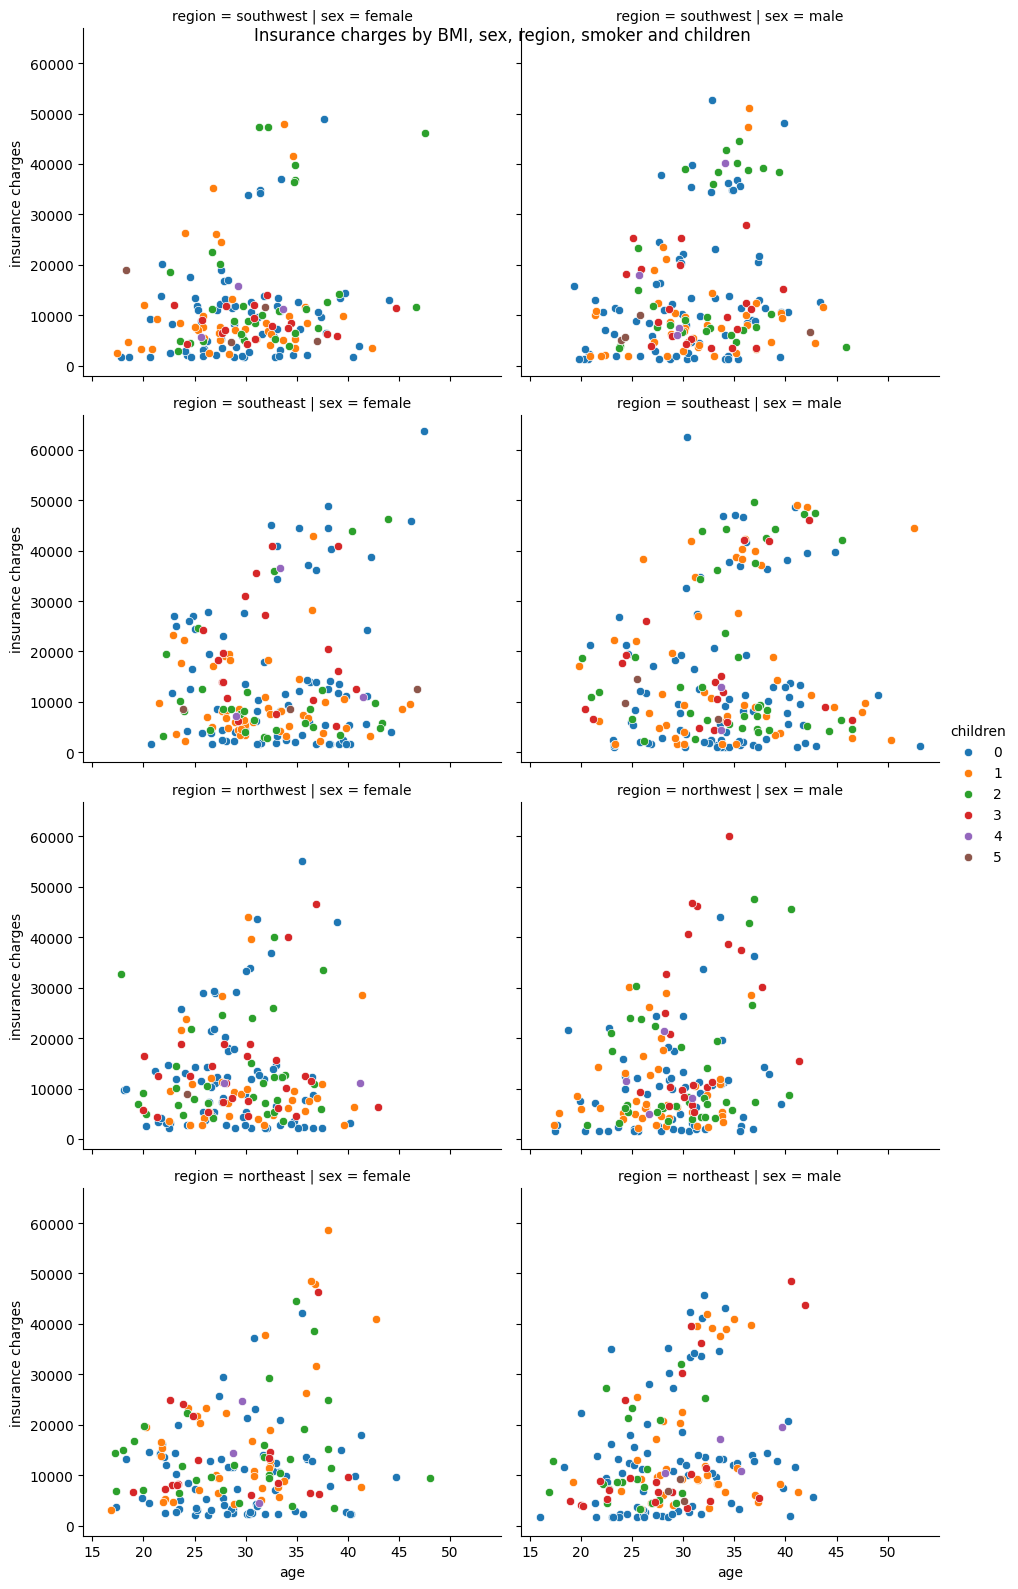

In [5]:
fg2 = sns.FacetGrid(insurance_data, col="sex", row="region", hue="children", height=4, aspect=1.2)
fg2.map(sns.scatterplot, "bmi", "charges")

# Add Legend
fg2.add_legend()

# Labels and title
fg2.set_axis_labels("age", "insurance charges")
fg2.fig.suptitle("Insurance charges by BMI, sex, region, smoker and children")

# Show plot
plt.show()

A linear model describes a linear relationship between an input and output variable. We therefore need to make sure that the problem we are looking to model with Linear Regression indeed has a continuos input and output variable with a linear relationship 

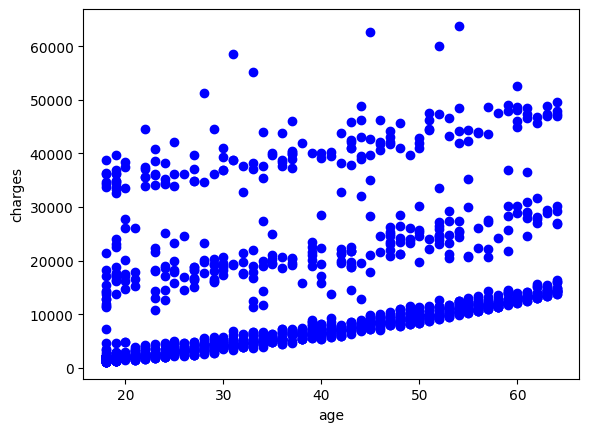

In [6]:
# The iloc function allows us to select rows from teh dataframe for plotting
x = insurance_data.iloc[:,:1].values
y = insurance_data.iloc[:,-1].values

plt.scatter(x,y,color = 'b')
plt.xlabel('age')
plt.ylabel('charges')
plt.show()


Plot another scatter plot with the best line fit. Now that we have determined the relationship we will fit a simple linear regression model using sklearn

In [7]:
# Fit the model
insurance_model = LinearRegression()
insurance_model.fit(x,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


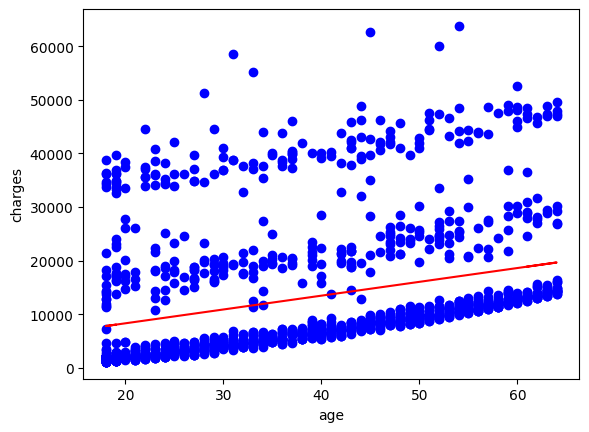

In [8]:
# Plot the data and model
y_pred = insurance_model.predict(x)

plt.scatter(x,y,color = 'b')
plt.plot(x,y_pred,color = 'r')
plt.xlabel('age')
plt.ylabel('charges')
plt.show()